In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

In [3]:
df = pd.read_csv('cleaned_netflix_data.csv')

In [4]:
df['date_added'] = pd.to_datetime(df['date_added'])
df['year_added'] = df['date_added'].dt.year

In [5]:
print("="*40)
print("NETFLIX DATASET SUMMARY STATISTICS")
print("="*40)
print(f"Total Titles: {len(df)}")
print(f"Total Movies: {len(df[df['type'] == 'Movie'])}")
print(f"Total TV Shows: {len(df[df['type'] == 'TV Show'])}")
print("="*40)

NETFLIX DATASET SUMMARY STATISTICS
Total Titles: 7770
Total Movies: 5372
Total TV Shows: 2398


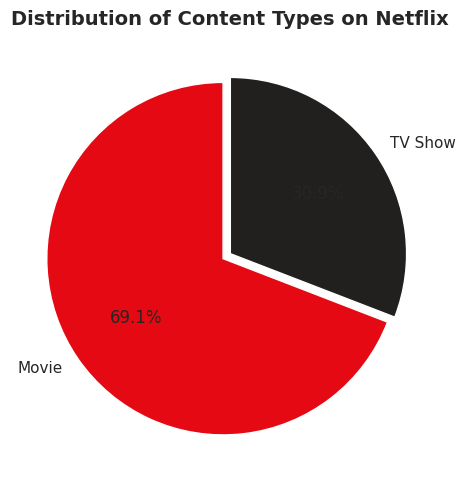

In [6]:
# ---------------------------------------------------
# Chart 1: Content Type Distribution (Movies vs TV Shows)
# ---------------------------------------------------
plt.figure(figsize=(7, 5))
type_counts = df['type'].value_counts()
plt.pie(type_counts, labels=type_counts.index, autopct='%1.1f%%', colors=['#e50914', '#221f1f'], startangle=90, explode=(0.05, 0))
plt.title('Distribution of Content Types on Netflix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('chart1_content_type.png')
plt.show()

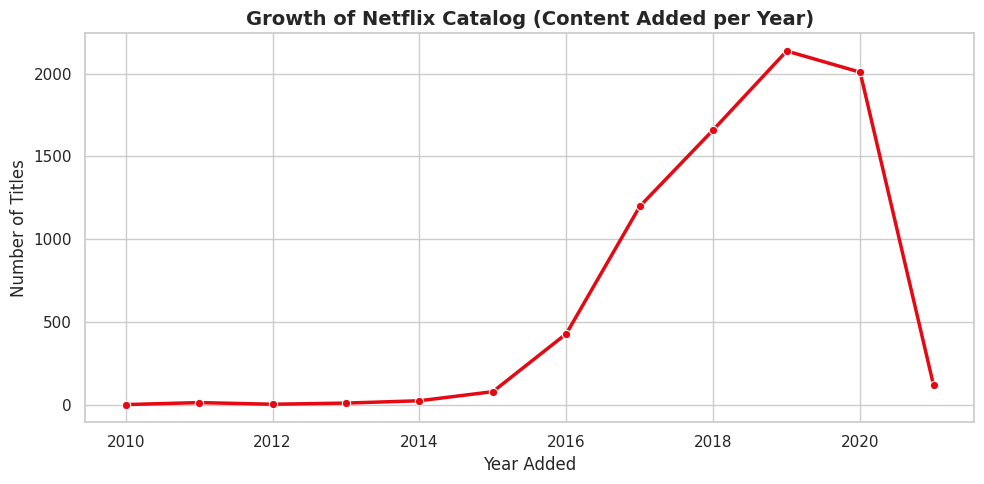

In [7]:
# ---------------------------------------------------
# Chart 2: Content Addition Trend Over the Years
# ---------------------------------------------------
plt.figure(figsize=(10, 5))
yearly_data = df[df['year_added'] >= 2010]['year_added'].value_counts().sort_index()
sns.lineplot(x=yearly_data.index.astype(int), y=yearly_data.values, marker='o', color='#e50914', linewidth=2.5)
plt.title('Growth of Netflix Catalog (Content Added per Year)', fontsize=14, fontweight='bold')
plt.xlabel('Year Added')
plt.ylabel('Number of Titles')
plt.tight_layout()
plt.savefig('chart2_yearly_trend.png')
plt.show()

/tmp/ipykernel_532/1189151606.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_countries.values, y=top_countries.index, palette='Reds_r')


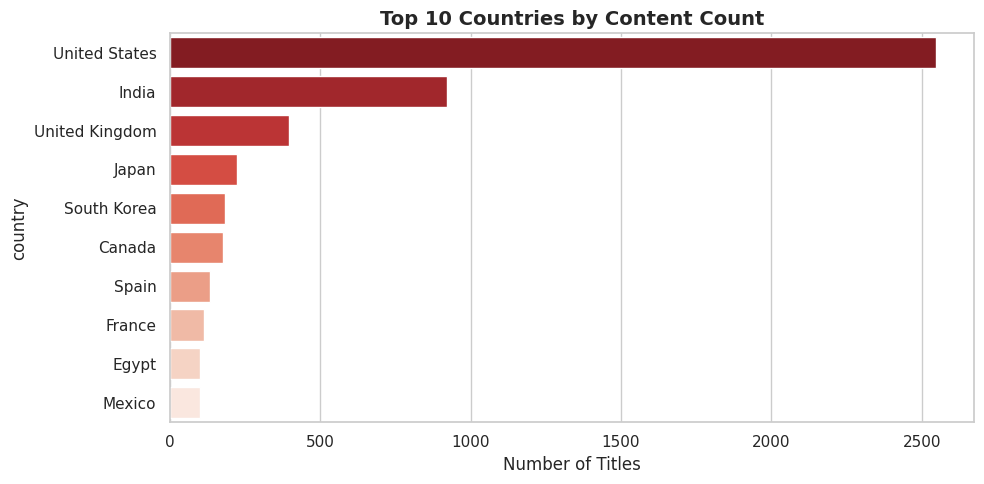

In [8]:
# ---------------------------------------------------
# Chart 3: Top 10 Content Producing Countries
# ---------------------------------------------------
plt.figure(figsize=(10, 5))
top_countries = df[df['country'] != 'Unknown']['country'].value_counts().head(10)
sns.barplot(x=top_countries.values, y=top_countries.index, palette='Reds_r')
plt.title('Top 10 Countries by Content Count', fontsize=14, fontweight='bold')
plt.xlabel('Number of Titles')
plt.tight_layout()
plt.savefig('chart3_top_countries.png')
plt.show()

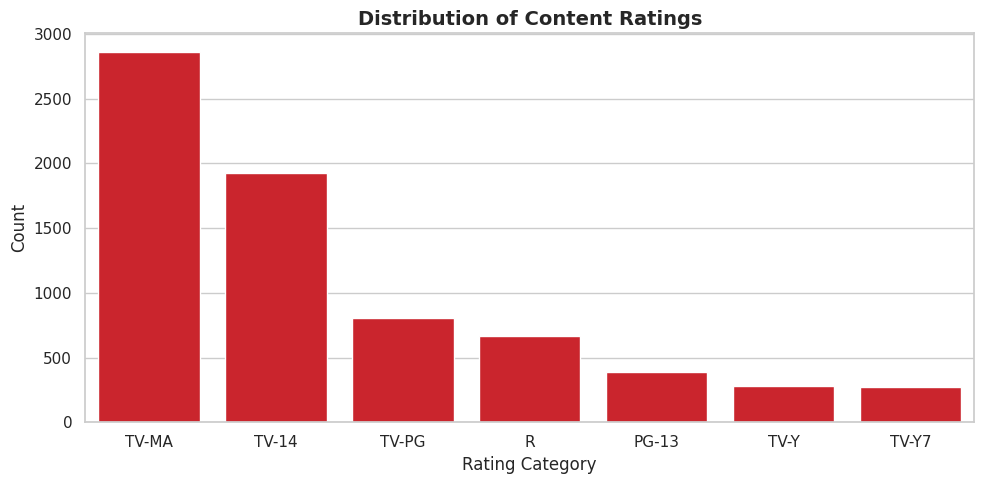

In [9]:
# ---------------------------------------------------
# Chart 4: Rating Distribution (Audience Target)
# ---------------------------------------------------
plt.figure(figsize=(10, 5))
top_ratings = df['rating'].value_counts().head(7)
sns.barplot(x=top_ratings.index, y=top_ratings.values, color='#e50914')
plt.title('Distribution of Content Ratings', fontsize=14, fontweight='bold')
plt.xlabel('Rating Category')
plt.ylabel('Count')
plt.tight_layout()
plt.savefig('chart4_ratings.png')
plt.show()